# DSC 478 Final Project

## Tyler Chambers

In [249]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### YouTube Comment Scraping

In [250]:
import googleapiclient.discovery

### Data Preparation

In [251]:
## Data from data.world acquired from internet
df_dataworld = pd.read_excel('Final_Project_Internet_Dataset.xlsx')
df_dataworld.head()

,Source.Name,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS
0,Youtube01-Psy.csv,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07 06:20:48,"Huh, anyway check out this you[tube] channel: ...",1.0
1,Youtube01-Psy.csv,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07 12:37:15,Hey guys check out my new channel and our firs...,1.0
2,Youtube01-Psy.csv,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08 17:34:21,just for test I have to say murdev.com,1.0
3,Youtube01-Psy.csv,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09 08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1.0
4,Youtube01-Psy.csv,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10 16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1.0


In [252]:
## removing unnecesary columns and changing spam/not spam classes
df_dataworld_small = df_dataworld[['CONTENT','CLASS']]
df_dataworld_small["CLASS"] = df_dataworld_small["CLASS"].replace(to_replace=1.0, value=True)
df_dataworld_small["CLASS"] = df_dataworld_small["CLASS"].replace(to_replace=0.0, value=False)
df_dataworld_small.head()

C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\2945298198.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dataworld_small["CLASS"] = df_dataworld_small["CLASS"].replace(to_replace=1.0, value=True)
C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\2945298198.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dataworld_small["CLASS"] = df_dataworld_small["CLASS"].replace(to_replace=0.0, value=False)


,CONTENT,CLASS
0,"Huh, anyway check out this you[tube] channel: ...",True
1,Hey guys check out my new channel and our firs...,True
2,just for test I have to say murdev.com,True
3,me shaking my sexy ass on my channel enjoy ^_^ ﻿,True
4,watch?v=vtaRGgvGtWQ Check this out .﻿,True


In [253]:
## Data collected using YouTube API
df_collected = pd.read_excel('Final Project Full Collected Dataset.xlsx')
df_collected.head()

,Source.Name,author,updated_at,like_count,text,class
0,AFA.csv,@AustorFIFA,2024-11-18 15:44:00,19,*Like & SIUUUUbscribe* to keep yourself up to ...,False
1,AFA.csv,@dawnkuppan,2024-11-19 13:40:41,0,Ronaldo going back to sporting Lisbon for one ...,False
2,AFA.csv,@eesa5204,2024-11-19 13:32:54,0,Any1 gonna talk about zirkzee,False
3,AFA.csv,@ThatRelevantDude,2024-11-19 12:32:03,0,YES BRO 524 SUBS,False
4,AFA.csv,@mariussilahviravong4231,2024-11-19 11:11:24,0,W video,False


In [254]:
## Removing unnecessary columns
df_collected_small= df_collected[["text","class"]]
df_collected_small

,text,class
0,*Like & SIUUUUbscribe* to keep yourself up to ...,False
1,Ronaldo going back to sporting Lisbon for one ...,False
2,Any1 gonna talk about zirkzee,False
3,YES BRO 524 SUBS,False
4,W video,False
...,...,...
5776,Uwu,False
5777,My way is the editor. I know it's questionable...,False
5778,pls teach me,False
5779,Saving all the saves!,False


In [255]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
#nltk.download("punkt")
#nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

In [256]:
## Tokenizing data.world data and removing common words
df_dataworld_small["clean_text"] = df_dataworld_small["CONTENT"].apply(word_tokenize)
for i in range(len(df_dataworld_small["clean_text"])):
    df_dataworld_small["clean_text"][i] = [word for word in df_dataworld_small["clean_text"][i] if word.lower() not in stop_words]
for i in range(len(df_dataworld_small["clean_text"])):
    df_dataworld_small["clean_text"][i] = " ".join(df_dataworld_small["clean_text"][i])
df_dataworld_small.head()

C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\2435133089.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dataworld_small["clean_text"] = df_dataworld_small["CONTENT"].apply(word_tokenize)
C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\2435133089.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dataworld_small["clean_text"][i] = [word for word in df_dataworld_small["clean_text"][i] if word.lower() not in stop_words]
C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\2435133089.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy 

,CONTENT,CLASS,clean_text
0,"Huh, anyway check out this you[tube] channel: ...",True,"Huh , anyway check [ tube ] channel : kobyoshi02"
1,Hey guys check out my new channel and our firs...,True,Hey guys check new channel first vid US MONKEY...
2,just for test I have to say murdev.com,True,test say murdev.com
3,me shaking my sexy ass on my channel enjoy ^_^ ﻿,True,shaking sexy ass channel enjoy ^_^ ﻿
4,watch?v=vtaRGgvGtWQ Check this out .﻿,True,watch ? v=vtaRGgvGtWQ Check .﻿


In [257]:
## Tokenizing collected data and removing common words
for i in range(len(df_collected_small["text"])):
    df_collected_small["text"][i] = str(df_collected_small["text"][i])
df_collected_small["clean_text"] = df_collected_small["text"].apply(word_tokenize)
for i in range(len(df_collected_small["clean_text"])):
    df_collected_small["clean_text"][i] = [word for word in df_collected_small["clean_text"][i] if word.lower() not in stop_words]
for i in range(len(df_collected_small["clean_text"])):
    df_collected_small["clean_text"][i] = " ".join(df_collected_small["clean_text"][i])
df_collected_small.head()

C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\3438150561.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_collected_small["text"][i] = str(df_collected_small["text"][i])
C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\3438150561.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_collected_small["clean_text"] = df_collected_small["text"].apply(word_tokenize)
C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\3438150561.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentati

,text,class,clean_text
0,*Like & SIUUUUbscribe* to keep yourself up to ...,False,* Like & SIUUUUbscribe * keep date Football Tr...
1,Ronaldo going back to sporting Lisbon for one ...,False,Ronaldo going back sporting Lisbon one last da...
2,Any1 gonna talk about zirkzee,False,Any1 gon na talk zirkzee
3,YES BRO 524 SUBS,False,YES BRO 524 SUBS
4,W video,False,W video


In [258]:
## Removing original text columns
df_collected_final = df_collected_small[["clean_text", "class"]]
display(df_collected_final.head())
df_dataworld_final = df_dataworld_small[["clean_text", "CLASS"]]
df_dataworld_final.columns = ["clean_text", "class"]
df_dataworld_final.head()

,clean_text,class
0,* Like & SIUUUUbscribe * keep date Football Tr...,False
1,Ronaldo going back sporting Lisbon one last da...,False
2,Any1 gon na talk zirkzee,False
3,YES BRO 524 SUBS,False
4,W video,False


,clean_text,class
0,"Huh , anyway check [ tube ] channel : kobyoshi02",True
1,Hey guys check new channel first vid US MONKEY...,True
2,test say murdev.com,True
3,shaking sexy ass channel enjoy ^_^ ﻿,True
4,watch ? v=vtaRGgvGtWQ Check .﻿,True


In [259]:
## Combining two datasets
df_combined_data = pd.concat([df_dataworld_final, df_collected_final])
df_combined = df_combined_data.reset_index(drop = True)
df_combined

,clean_text,class
0,"Huh , anyway check [ tube ] channel : kobyoshi02",True
1,Hey guys check new channel first vid US MONKEY...,True
2,test say murdev.com,True
3,shaking sexy ass channel enjoy ^_^ ﻿,True
4,watch ? v=vtaRGgvGtWQ Check .﻿,True
...,...,...
7737,Uwu,False
7738,way editor . know 's questionable way everyone...,False
7739,pls teach,False
7740,Saving saves !,False


In [260]:
## This is where we need to split to recover the original two datasets
df_combined["clean_text"][1961]

'* Like & SIUUUUbscribe * keep date Football Transfers Football News ! _x000D_ _x000D_ 3 Days Ago - > NEW CONFIRMED TRANSFERS & RUMOURS ! - > https : //youtu.be/nVGX5B7y6Zo_x000D_ Confirmed Summer Transfers 2024 - > https : //youtu.be/nTjlLOp5uOw'

In [261]:
## Term document matrix creation
## Code from here: https://okan.cloud/posts/2021-04-08-text-vectorization-using-python-term-document-matrix/
from sklearn.feature_extraction.text import CountVectorizer
vect = CountVectorizer()  
vects = vect.fit_transform(df_combined["clean_text"])

td = pd.DataFrame(vects.todense())
td.columns = vect.get_feature_names_out()
term_document_matrix = td.T
term_document_matrix.columns = ['Doc '+str(i) for i in range(len(df_combined["clean_text"]))]
term_document_matrix['total_count'] = term_document_matrix.sum(axis=1)

term_document_matrix = term_document_matrix.sort_values(by ='total_count',ascending=False)
term_document_matrix.head()

,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4,Doc 5,Doc 6,Doc 7,Doc 8,Doc 9,...,Doc 7733,Doc 7734,Doc 7735,Doc 7736,Doc 7737,Doc 7738,Doc 7739,Doc 7740,Doc 7741,total_count
video,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,611
like,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,610
check,1,1,0,0,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,590
love,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,505
please,0,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,390


In [263]:
## Document term matrix creation
term_document_matrix = term_document_matrix.drop("total_count",axis = 1)
document_term_matrix = term_document_matrix.T
document_term_matrix

,video,like,check,love,please,game,one,song,com,youtube,...,d15fb87973,mullet,muller,muito,d22,mud,d3,mu,d4aaacwk,𝚟𝚒𝚎𝚠
Doc 0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Doc 1,0,1,1,0,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Doc 2,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
Doc 3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Doc 4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Doc 7737,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Doc 7738,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Doc 7739,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Doc 7740,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [339]:
## Term Frequency Table
termFreqs = term_document_matrix.sum(axis=1)
df_totsum = pd.DataFrame(termFreqs, columns = [ "Count"])
df_totsum.sort_values("Count", ascending = False).head(20)

,Count
video,611
like,610
check,590
love,505
please,390
game,359
one,339
song,316
com,305
youtube,287


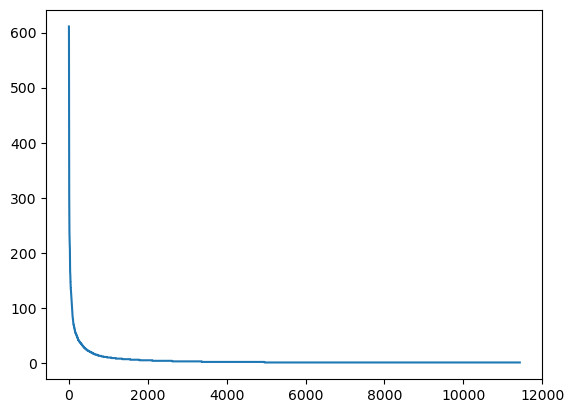

In [340]:
## Term Frequency Plot
plt.plot(sorted(termFreqs, reverse=True))
plt.show()

In [264]:
## Applying TF-IDF on the data matrix
counts = pd.DataFrame([(document_term_matrix!=0).sum(1)]).T
NMatrix=np.ones(np.shape(document_term_matrix), dtype=float)*len(document_term_matrix["video"])
IDF = np.log2(np.divide(NMatrix, np.array(counts)))
tfidf_data = document_term_matrix * IDF
tfidf_data.head()

C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\3326115312.py:4: RuntimeWarning: divide by zero encountered in divide
  IDF = np.log2(np.divide(NMatrix, np.array(counts)))


,video,like,check,love,please,game,one,song,com,youtube,...,d15fb87973,mullet,muller,muito,d22,mud,d3,mu,d4aaacwk,𝚟𝚒𝚎𝚠
Doc 0,0.0,0.000000,10.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Doc 1,0.0,8.831028,8.831028,0.0,17.662056,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Doc 2,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,10.918491,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Doc 3,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Doc 4,0.0,0.000000,11.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [265]:
## Acquiring the classes in a dataset
tfidf_class = df_combined["class"]
tfidf_class.head()

0    True
1    True
2    True
3    True
4    True
Name: class, dtype: object

In [266]:
## Changing True/False from boolean to string
tfidf_list = list(tfidf_class)
tfidf_classlist = []
for i in tfidf_list:
    if i == True:
        tfidf_classlist.append("True")
    else:
        tfidf_classlist.append("False")

In [267]:
## Creating dataset of matrix and class
df_document_dataframe = tfidf_data
df_document_dataframe["spam_class"] = tfidf_classlist
df_document_dataframe

,video,like,check,love,please,game,one,song,com,youtube,...,mullet,muller,muito,d22,mud,d3,mu,d4aaacwk,𝚟𝚒𝚎𝚠,spam_class
Doc 0,0.0,0.000000,10.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 1,0.0,8.831028,8.831028,0.0,17.662056,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 2,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,10.918491,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 3,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 4,0.0,0.000000,11.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Doc 7737,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
Doc 7738,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
Doc 7739,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
Doc 7740,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False


In [268]:
## Export dataset
## DO NOT OPEN UNLESS NECESSARY
## May crash computer
## Do not need to export, dataset will be given
## df_document_dataframe.to_csv('Final Project Dataset.csv')

In [269]:
## load in dataset
## DO NOT OPEN UNLESS NECESSARY
## May crash computer
tfidf_matrix = pd.read_csv('Final Project Dataset.csv')
tfidf_matrix

,Unnamed: 0,video,like,check,love,please,game,one,song,com,...,mullet,muller,muito,d22,mud,d3,mu,d4aaacwk,𝚟𝚒𝚎𝚠,spam_class
0,Doc 0,0.0,0.000000,10.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
1,Doc 1,0.0,8.831028,8.831028,0.0,17.662056,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
2,Doc 2,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,10.918491,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
3,Doc 3,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
4,Doc 4,0.0,0.000000,11.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7737,Doc 7737,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
7738,Doc 7738,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
7739,Doc 7739,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
7740,Doc 7740,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False


In [270]:
## set first column as row indices
tfidf_mat = tfidf_matrix.copy()
tfidf_mat.set_index("Unnamed: 0", inplace = True)
tfidf_mat

,video,like,check,love,please,game,one,song,com,youtube,...,mullet,muller,muito,d22,mud,d3,mu,d4aaacwk,𝚟𝚒𝚎𝚠,spam_class
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
Doc 0,0.0,0.000000,10.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 1,0.0,8.831028,8.831028,0.0,17.662056,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 2,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,10.918491,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 3,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
Doc 4,0.0,0.000000,11.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Doc 7737,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
Doc 7738,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False
Doc 7739,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False


In [271]:
## Changes True/False to "Spam" and "Not Spam"
for i in range(len(tfidf_mat["spam_class"])):
    if tfidf_mat["spam_class"][i] == True:
        tfidf_mat["spam_class"][i] = "Spam"
    else:
        tfidf_mat["spam_class"][i] = "Not Spam"
tfidf_mat

C:\Users\jckc1\AppData\Local\Temp\ipykernel_18968\3433024843.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tfidf_mat["spam_class"][i] = "Spam"


,video,like,check,love,please,game,one,song,com,youtube,...,mullet,muller,muito,d22,mud,d3,mu,d4aaacwk,𝚟𝚒𝚎𝚠,spam_class
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
Doc 0,0.0,0.000000,10.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Spam
Doc 1,0.0,8.831028,8.831028,0.0,17.662056,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Spam
Doc 2,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,10.918491,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Spam
Doc 3,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Spam
Doc 4,0.0,0.000000,11.333528,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Spam
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Doc 7737,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Not Spam
Doc 7738,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Not Spam
Doc 7739,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Not Spam


In [341]:
## Value counts of spam and not spam
tfidf_mat["spam_class"].value_counts()

Not Spam    6621
Spam        1121
Name: spam_class, dtype: int64

In [342]:
## IF ANY OF THE ABOVE CODE DOES NOT WORK, USE FOLLOWING DATASET AND START HERE
## Dataset should be in attached files
## tfidf_mat.to_csv('tfidf_mat.csv')

In [ ]:
## IF ANY OF THE ABOVE CODE DOES NOT WORK, USE FOLLOWING DATASET AND START HERE
## tfidf_mat = pd.read_csv('tfidf_mat.csv')

### Train/Test Split and Model Preparation

In [272]:
## random train/test split
from sklearn.model_selection import train_test_split
tfidf_mat_train, tfidf_mat_test = train_test_split(tfidf_mat, test_size=0.2, random_state=234879)

In [273]:
print(tfidf_mat_train.shape)
tfidf_mat_test.shape

(6193, 11433)


(1549, 11433)

In [274]:
## old vs. new train/test split
tfidf_mat_old = tfidf_mat.iloc[0:1961]
tfidf_mat_new = tfidf_mat.iloc[1961:]

In [275]:
print(tfidf_mat_old.shape)
tfidf_mat_new.shape

(1961, 11433)


(5781, 11433)

In [276]:
## Separating class and matrix for training set
train_class = tfidf_mat_train["spam_class"]
tfidf_train_mat = tfidf_mat_train.drop("spam_class", axis = 1)
tfidf_train_mat.replace(np.nan,0, inplace = True)

In [277]:
## Separating class and matrix for test set
test_class = tfidf_mat_test["spam_class"]
tfidf_test_mat = tfidf_mat_test.drop("spam_class", axis = 1)
tfidf_test_mat.replace(np.nan,0, inplace = True)

In [278]:
## Separating class and matrix for old set
old_class = tfidf_mat_old["spam_class"]
tfidf_old_mat = tfidf_mat_old.drop("spam_class", axis = 1)
tfidf_old_mat.replace(np.nan,0, inplace = True)

In [279]:
## Separating class and matrix for new set
new_class = tfidf_mat_new["spam_class"]
tfidf_new_mat = tfidf_mat_new.drop("spam_class", axis = 1)
tfidf_new_mat.replace(np.nan,0, inplace = True)

In [280]:
print(train_class.value_counts())
print(test_class.value_counts())
print(old_class.value_counts())
new_class.value_counts()

Not Spam    5309
Spam         884
Name: spam_class, dtype: int64
Not Spam    1312
Spam         237
Name: spam_class, dtype: int64
Spam        1004
Not Spam     957
Name: spam_class, dtype: int64


Not Spam    5664
Spam         117
Name: spam_class, dtype: int64

In [345]:
## Oversampling the training set of the train/test split
from imblearn.over_sampling import RandomOverSampler


# Initialize the RandomOverSampler
ros = RandomOverSampler(random_state=42)

# Fit and apply the transform
train_resampled, train_class_resampled = ros.fit_resample(tfidf_train_mat, train_class)

display(train_class_resampled.value_counts())
display(train_resampled.head())

Not Spam    5309
Spam        5309
Name: spam_class, dtype: int64

,video,like,check,love,please,game,one,song,com,youtube,...,d15fb87973,mullet,muller,muito,d22,mud,d3,mu,d4aaacwk,𝚟𝚒𝚎𝚠
0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,10.918491,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [281]:
from sklearn import neighbors, tree, naive_bayes

In [282]:
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

### KNN Model

In [360]:
## Using best knn parameters on train/test data
k = 4

knnclf = neighbors.KNeighborsClassifier(k, weights='distance', metric='cosine')
knnclf.fit(train_resampled, train_class_resampled)

KNeighborsClassifier(metric='cosine', n_neighbors=4, weights='distance')

In [361]:
## predicting training set of train/test data 
knn_split_train = knnclf.predict(train_resampled)

In [362]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score

In [363]:
## classification report of training set of train/test
print(classification_report(train_class_resampled, knn_split_train))
recall_score(train_class_resampled, knn_split_train, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       1.00      0.99      0.99      5309
        Spam       0.99      1.00      0.99      5309

    accuracy                           0.99     10618
   macro avg       0.99      0.99      0.99     10618
weighted avg       0.99      0.99      0.99     10618



1.0

In [364]:
## predicting test set of train/test data
knn_split_test = knnclf.predict(tfidf_test_mat)

In [365]:
## classification report of test set of train/test
print(classification_report(test_class, knn_split_test))
recall_score(test_class, knn_split_test, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.88      0.93      1312
        Spam       0.58      0.89      0.70       237

    accuracy                           0.88      1549
   macro avg       0.78      0.89      0.81      1549
weighted avg       0.92      0.88      0.89      1549



0.890295358649789

In [366]:
## confusion matrix of test set
print(confusion_matrix(test_class, knn_split_test))

[[1157  155]
 [  26  211]]


In [296]:
## Creating model for old/new data
knnoldvnew = neighbors.KNeighborsClassifier(k, weights='distance', metric='cosine')
knnoldvnew.fit(tfidf_old_mat, old_class)

KNeighborsClassifier(metric='cosine', n_neighbors=4, weights='distance')

In [297]:
## Predicting old set of old/new data
knn_oldnew_train = knnclf.predict(tfidf_old_mat)

In [298]:
## classification report of old set of old/new data
print(classification_report(old_class, knn_oldnew_train))
recall_score(old_class, knn_oldnew_train, pos_label = "Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.99      0.98       957
        Spam       0.99      0.98      0.98      1004

    accuracy                           0.98      1961
   macro avg       0.98      0.98      0.98      1961
weighted avg       0.98      0.98      0.98      1961



0.9770916334661355

In [299]:
## Predicting new set of old/new data
knn_oldnew_test = knnclf.predict(tfidf_new_mat)

In [300]:
## classification report of new set of old/new data
print(classification_report(new_class, knn_oldnew_test))
print(confusion_matrix(new_class, knn_oldnew_test))
recall_score(new_class, knn_oldnew_test, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       1.00      1.00      1.00      5664
        Spam       0.88      0.83      0.85       117

    accuracy                           0.99      5781
   macro avg       0.94      0.91      0.93      5781
weighted avg       0.99      0.99      0.99      5781

[[5651   13]
 [  20   97]]


0.8290598290598291

### Naive Bayes

In [387]:
## Using naive bayes on train/test data
bayes = naive_bayes.GaussianNB()
bayes_traintest = bayes.fit(train_resampled, train_class_resampled)
bayes_testpredict = bayes_traintest.predict(tfidf_test_mat)
bayes_trainpredict = bayes_traintest.predict(train_resampled)

In [388]:
## Classification report of training set on train/test data
print(classification_report(train_class_resampled, bayes_trainpredict))
print(bayes_traintest.score(train_resampled, train_class_resampled))
recall_score(train_class_resampled, bayes_trainpredict, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       1.00      0.83      0.91      5309
        Spam       0.85      1.00      0.92      5309

    accuracy                           0.91     10618
   macro avg       0.93      0.91      0.91     10618
weighted avg       0.93      0.91      0.91     10618

0.9148615558485591


1.0

In [389]:
## Classification report of test set on train/test data
print(classification_report(test_class, bayes_testpredict))
print(bayes_traintest.score(tfidf_test_mat, test_class))
recall_score(test_class, bayes_testpredict, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.94      0.74      0.83      1312
        Spam       0.34      0.76      0.47       237

    accuracy                           0.74      1549
   macro avg       0.64      0.75      0.65      1549
weighted avg       0.85      0.74      0.77      1549

0.7404777275661717


0.759493670886076

In [304]:
## Using naive bayes on old/new data
bayes = naive_bayes.GaussianNB()
bayes_oldnew = bayes.fit(tfidf_old_mat, old_class)
bayes_newpredict = bayes_oldnew.predict(tfidf_new_mat)
bayes_oldpredict = bayes_oldnew.predict(tfidf_old_mat)

In [305]:
## Classification report of old set on old/new data
print(classification_report(old_class, bayes_oldpredict))
print(bayes_oldnew.score(tfidf_old_mat, old_class))
recall_score(old_class, bayes_oldpredict, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.81      1.00      0.90       957
        Spam       1.00      0.78      0.88      1004

    accuracy                           0.89      1961
   macro avg       0.91      0.89      0.89      1961
weighted avg       0.91      0.89      0.89      1961

0.8883222845486997


0.7818725099601593

In [306]:
## Classification report of new set on old/new data
print(classification_report(new_class, bayes_newpredict))
print(confusion_matrix(new_class, bayes_newpredict))
print(bayes_oldnew.score(tfidf_new_mat, new_class))
recall_score(new_class, bayes_newpredict, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.57      0.72      5664
        Spam       0.03      0.56      0.05       117

    accuracy                           0.57      5781
   macro avg       0.50      0.56      0.38      5781
weighted avg       0.96      0.57      0.71      5781

[[3206 2458]
 [  52   65]]
0.5658190624459436


0.5555555555555556

### Decision Tree

In [427]:
## Decision tree of train/test dataset
treeclass = tree.DecisionTreeClassifier(criterion='entropy', min_samples_split=1)
tree_traintest = treeclass.fit(train_resampled, train_class_resampled)

In [428]:
## Decision tree predictions of training and testing using train/test set
treepred_test = tree_traintest.predict(tfidf_test_mat)
treepred_train = tree_traintest.predict(train_resampled)

In [429]:
## Classification report of training set of train/test data
print(classification_report(train_class_resampled, treepred_train))
recall_score(train_class_resampled, treepred_train, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       1.00      1.00      1.00      5309
        Spam       1.00      1.00      1.00      5309

    accuracy                           1.00     10618
   macro avg       1.00      1.00      1.00     10618
weighted avg       1.00      1.00      1.00     10618



1.0

In [430]:
## Classification report of test set of train/test data
print(classification_report(test_class, treepred_test))
recall_score(test_class, treepred_test, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.97      0.97      0.97      1312
        Spam       0.83      0.84      0.83       237

    accuracy                           0.95      1549
   macro avg       0.90      0.90      0.90      1549
weighted avg       0.95      0.95      0.95      1549



0.8396624472573839

In [431]:
## Decision tree of old/new dataset
tree_oldnew = treeclass.fit(tfidf_old_mat, old_class)
treepred_old = tree_oldnew.predict(tfidf_old_mat)
treepred_new = tree_oldnew.predict(tfidf_new_mat)

In [432]:
## Classification report of old set of old/new data
print(classification_report(old_class, treepred_old))
recall_score(old_class, treepred_old, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       1.00      1.00      1.00       957
        Spam       1.00      1.00      1.00      1004

    accuracy                           1.00      1961
   macro avg       1.00      1.00      1.00      1961
weighted avg       1.00      1.00      1.00      1961



1.0

In [433]:
## Classification report of new set of old/new data
print(classification_report(new_class, treepred_new))
print(confusion_matrix(new_class, treepred_new))
recall_score(new_class, treepred_new, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.92      0.95      5664
        Spam       0.04      0.18      0.07       117

    accuracy                           0.91      5781
   macro avg       0.51      0.55      0.51      5781
weighted avg       0.96      0.91      0.93      5781

[[5215  449]
 [  96   21]]


0.1794871794871795

### Random Forest Model

In [314]:
from sklearn.ensemble import RandomForestClassifier

In [442]:
## Random forest of train/test data and old/new data split
rf = RandomForestClassifier(n_estimators=1001, random_state=42, max_depth=3)
rf_traintest = rf.fit(train_resampled, train_class_resampled)
rf_oldnew = rf.fit(tfidf_old_mat, old_class)

In [443]:
## Predictions for random forests
rfpred_test = rf_traintest.predict(tfidf_test_mat)
rfpred_train = rf_traintest.predict(train_resampled)
rfpred_old = rf_oldnew.predict(tfidf_old_mat)
rfpred_new = rf_oldnew.predict(tfidf_new_mat)

In [444]:
## Classification report of training set for train/test data
print(classification_report(train_class_resampled, rfpred_train))
recall_score(train_class_resampled, rfpred_train, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.89      0.88      0.88      5309
        Spam       0.88      0.89      0.89      5309

    accuracy                           0.89     10618
   macro avg       0.89      0.89      0.89     10618
weighted avg       0.89      0.89      0.89     10618



0.8941420229798456

In [445]:
## Classification report of test set for train/test data
print(classification_report(test_class, rfpred_test))
recall_score(test_class, rfpred_test, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.86      0.91      1312
        Spam       0.53      0.89      0.67       237

    accuracy                           0.86      1549
   macro avg       0.76      0.87      0.79      1549
weighted avg       0.91      0.86      0.88      1549



0.890295358649789

In [440]:
## Classification report of old set for old/new data
print(classification_report(old_class, rfpred_old))
recall_score(old_class, rfpred_old, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.95      0.91      0.93       957
        Spam       0.92      0.96      0.94      1004

    accuracy                           0.94      1961
   macro avg       0.94      0.94      0.94      1961
weighted avg       0.94      0.94      0.94      1961



0.9581673306772909

In [441]:
## Classification report of new set for old/new data
print(classification_report(new_class, rfpred_new))
print(confusion_matrix(new_class, rfpred_new))
recall_score(new_class, rfpred_new, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.99      0.72      0.83      5664
        Spam       0.04      0.60      0.08       117

    accuracy                           0.72      5781
   macro avg       0.52      0.66      0.46      5781
weighted avg       0.97      0.72      0.82      5781

[[4088 1576]
 [  47   70]]


0.5982905982905983

### AdaBoost Model

In [321]:
from sklearn.ensemble import AdaBoostClassifier

In [446]:
## AdaBoost fitting
adaboost = AdaBoostClassifier()
boost_traintest = adaboost.fit(train_resampled, train_class_resampled)
boost_oldnew = adaboost.fit(tfidf_old_mat, old_class)

In [447]:
## Boost predictions for train/test and old/new set
boost_test = boost_traintest.predict(tfidf_test_mat)
boost_train = boost_traintest.predict(train_resampled)
boost_old = boost_oldnew.predict(tfidf_old_mat)
boost_new = boost_oldnew.predict(tfidf_new_mat)

In [448]:
## Classification matrix of train set for train/test data
print(classification_report(train_class_resampled, boost_train))
recall_score(train_class_resampled, boost_train, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.92      0.93      0.92      5309
        Spam       0.93      0.91      0.92      5309

    accuracy                           0.92     10618
   macro avg       0.92      0.92      0.92     10618
weighted avg       0.92      0.92      0.92     10618



0.9133546807308345

In [449]:
## Classification matrix of test set for train/test data
print(classification_report(test_class, boost_test))
recall_score(test_class, boost_test, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.92      0.95      1312
        Spam       0.67      0.90      0.77       237

    accuracy                           0.92      1549
   macro avg       0.83      0.91      0.86      1549
weighted avg       0.93      0.92      0.92      1549



0.8987341772151899

In [326]:
## Classification matrix of old set for old/new data
print(classification_report(old_class, boost_old))
recall_score(old_class, boost_old, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.97      0.98      0.97       957
        Spam       0.98      0.97      0.97      1004

    accuracy                           0.97      1961
   macro avg       0.97      0.97      0.97      1961
weighted avg       0.97      0.97      0.97      1961



0.9671314741035857

In [327]:
## Classification matrix of new set for old/new data
print(classification_report(new_class, boost_new))
print(confusion_matrix(new_class, boost_new))
recall_score(new_class, boost_new, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.99      0.92      0.95      5664
        Spam       0.10      0.43      0.17       117

    accuracy                           0.91      5781
   macro avg       0.55      0.68      0.56      5781
weighted avg       0.97      0.91      0.94      5781

[[5230  434]
 [  67   50]]


0.42735042735042733

### Ensemble Model

In [328]:
from sklearn.ensemble import VotingClassifier

In [464]:
## Ensemble model using multiple previous models
models = [('knn', neighbors.KNeighborsClassifier(6, weights='distance', metric='cosine')),
          #('bayes',naive_bayes.GaussianNB()),
          #('tree', tree.DecisionTreeClassifier(criterion='entropy', min_samples_split=1)),
          ('rf', RandomForestClassifier(n_estimators=1001, random_state=42, max_depth=2)),
          ('boost', AdaBoostClassifier())]

In [465]:
## Fitting ensemble models
voting_model = VotingClassifier(estimators=models, voting='hard')
voting_traintest = voting_model.fit(train_resampled, train_class_resampled)
voting_oldnew =  voting_model.fit(tfidf_old_mat, old_class)

In [466]:
## Predicting ensemble model for both train/test and old/new splits
ensemble_train = voting_traintest.predict(train_resampled)
ensemble_test = voting_traintest.predict(tfidf_test_mat)
ensemble_old = voting_oldnew.predict(tfidf_old_mat)
ensemble_new = voting_oldnew.predict(tfidf_new_mat)

In [467]:
## Classification report for training set of train/test dataset
print(classification_report(train_class_resampled, ensemble_train))
recall_score(train_class_resampled, ensemble_train, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.93      0.89      0.91      5309
        Spam       0.89      0.93      0.91      5309

    accuracy                           0.91     10618
   macro avg       0.91      0.91      0.91     10618
weighted avg       0.91      0.91      0.91     10618



0.931813900922961

In [468]:
## Classification report for training set of train/test dataset
print(classification_report(test_class, ensemble_test))
recall_score(test_class, ensemble_test, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.87      0.92      1312
        Spam       0.56      0.92      0.70       237

    accuracy                           0.88      1549
   macro avg       0.77      0.89      0.81      1549
weighted avg       0.92      0.88      0.89      1549



0.919831223628692

In [469]:
## Classification report for old set of old/new dataset
print(classification_report(old_class, ensemble_old))
recall_score(old_class, ensemble_old, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.98      0.98      0.98       957
        Spam       0.98      0.98      0.98      1004

    accuracy                           0.98      1961
   macro avg       0.98      0.98      0.98      1961
weighted avg       0.98      0.98      0.98      1961



0.9810756972111554

In [470]:
## Classification report for new set of old/new dataset
print(classification_report(new_class, ensemble_new))
print(confusion_matrix(new_class, ensemble_new))
recall_score(new_class, ensemble_new, pos_label="Spam")

              precision    recall  f1-score   support

    Not Spam       0.99      0.87      0.92      5664
        Spam       0.07      0.49      0.12       117

    accuracy                           0.86      5781
   macro avg       0.53      0.68      0.52      5781
weighted avg       0.97      0.86      0.91      5781

[[4908  756]
 [  60   57]]


0.48717948717948717